In [ ]:
!pip -q install kaggle

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle (1).json to kaggle (1).json


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "kaggle (1).json",
    "/root/.kaggle/kaggle (1).json"
)

os.chmod("/root/.kaggle/kaggle (1).json", 0o600)
!pip -q install kaggle

print("Kaggle configured successfully!")

Kaggle configured successfully!


In [ ]:
!kaggle datasets download -d shayanfazeli/heartbeat -p /content

Dataset URL: https://www.kaggle.com/datasets/shayanfazeli/heartbeat
License(s): unknown
100% 98.8M/98.8M [00:00<00:00, 117MB/s]



In [ ]:
!unzip -o /content/heartbeat.zip -d /content/ecg_data

Archive:  /content/heartbeat.zip
  inflating: /content/ecg_data/mitbih_test.csv  
  inflating: /content/ecg_data/mitbih_train.csv  
  inflating: /content/ecg_data/ptbdb_abnormal.csv  
  inflating: /content/ecg_data/ptbdb_normal.csv  


In [ ]:
import os

print(os.listdir("/content/ecg_data"))

['mitbih_train.csv', 'mitbih_test.csv', 'ptbdb_abnormal.csv', 'ptbdb_normal.csv']


In [ ]:
import pandas as pd
import os

data_path = "/content/ecg_data"

print("Files available:")
print(os.listdir(data_path))

train_df = pd.read_csv(os.path.join(data_path, "mitbih_train.csv"), header=None)
test_df = pd.read_csv(os.path.join(data_path, "mitbih_test.csv"), header=None)

print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nFirst 5 rows of training data:")
display(train_df.head())


Files available:
['mitbih_train.csv', 'mitbih_test.csv', 'ptbdb_abnormal.csv', 'ptbdb_normal.csv']

Training dataset shape: (87554, 188)
Testing dataset shape: (21892, 188)

First 5 rows of training data:


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:

class_names = {
    0: "Normal",
    1: "Supraventricular Ectopic",
    2: "Ventricular Ectopic",
    3: "Fusion Beat",
    4: "Unknown"
}

class_counts = train_df.iloc[:, -1].astype(int).value_counts().sort_index()

for label, count in class_counts.items():
    print(f"Class {label} - {class_names[label]}: {count} samples")


Class 0 - Normal: 72471 samples
Class 1 - Supraventricular Ectopic: 2223 samples
Class 2 - Ventricular Ectopic: 5788 samples
Class 3 - Fusion Beat: 641 samples
Class 4 - Unknown: 6431 samples


Data Cleaning Check

In [ ]:
import pandas as pd
import numpy as np

def inspect_data(df, name):
    print(f"\n--- {name} ---")
    print("Dataset shape:", df.shape)
    print("Missing values:", int(df.isna().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))

    numeric_df = df.apply(pd.to_numeric, errors="coerce")
    print("Non-numeric cells:", int(numeric_df.isna().sum().sum()))

    values = numeric_df.to_numpy(dtype=float)
    print("Infinite values:", int(np.isinf(values).sum()))

    labels = numeric_df.iloc[:, -1]
    print("Invalid labels:", int((~labels.isin([0, 1, 2, 3, 4])).sum()))

    signals = numeric_df.iloc[:, :-1].to_numpy(dtype=float)
    print("All signal values finite:", bool(np.isfinite(signals).all()))

inspect_data(train_df, "Training Dataset")
inspect_data(test_df, "Test Dataset")


--- Training Dataset ---
Dataset shape: (87554, 188)
Missing values: 0
Duplicate rows: 0
Non-numeric cells: 0
Infinite values: 0
Invalid labels: 0
All signal values finite: True

--- Test Dataset ---
Dataset shape: (21892, 188)
Missing values: 0
Duplicate rows: 0
Non-numeric cells: 0
Infinite values: 0
Invalid labels: 0
All signal values finite: True


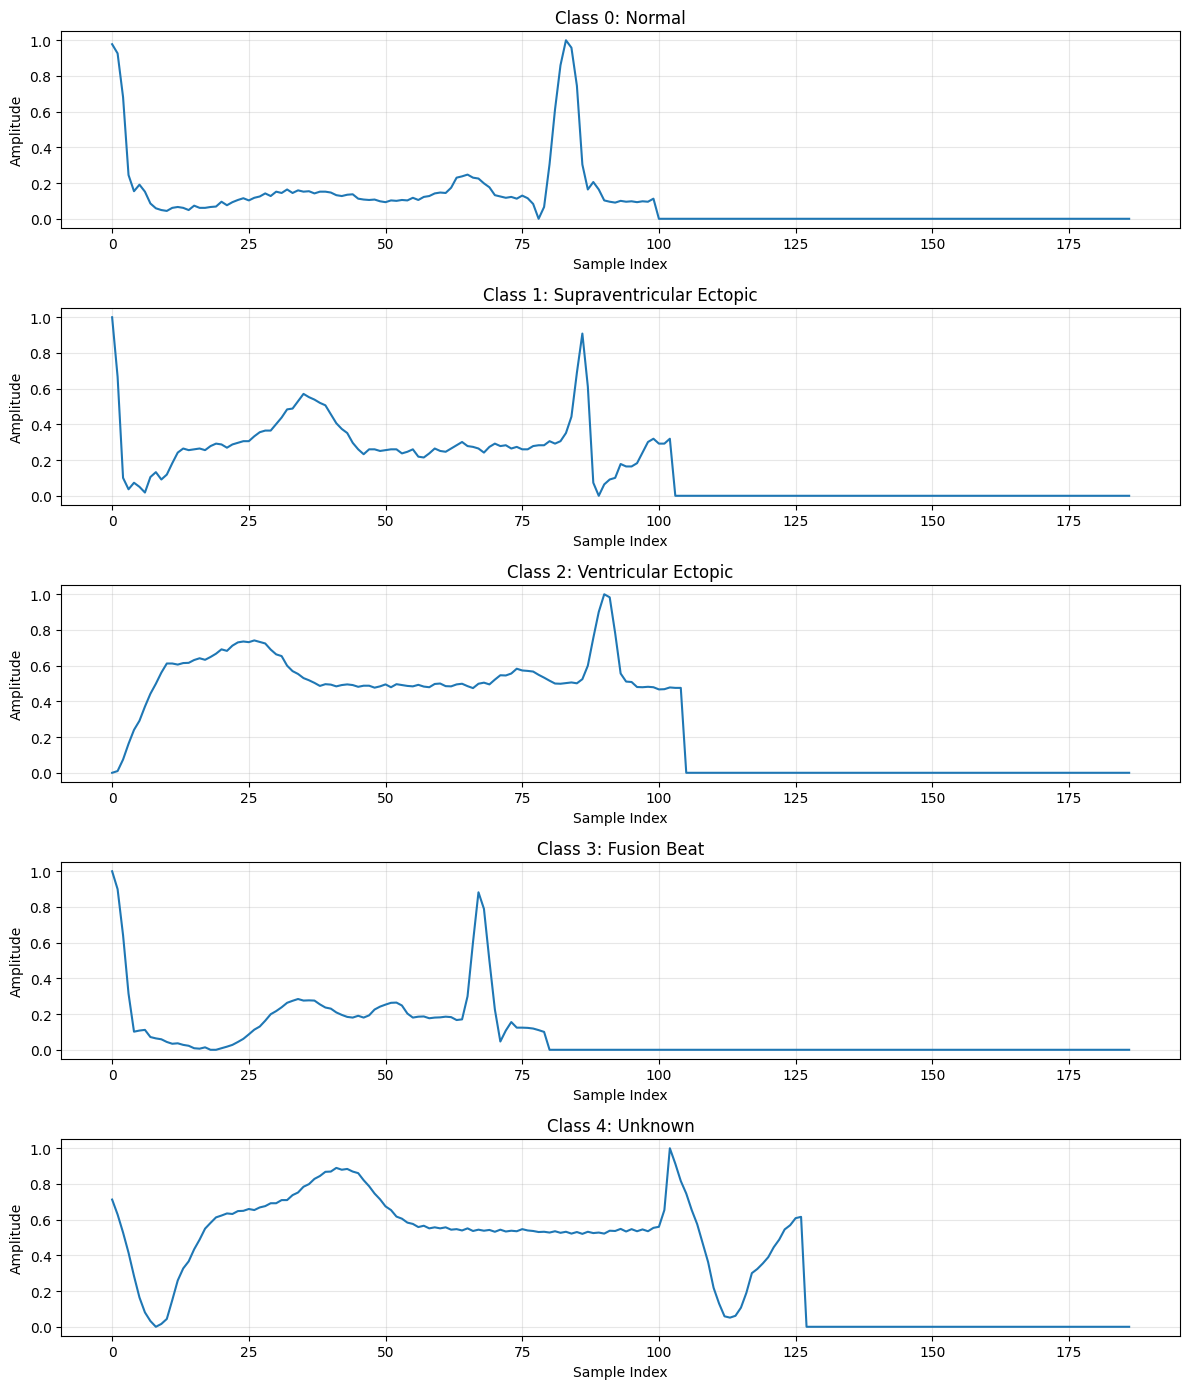

In [ ]:

import matplotlib.pyplot as plt

class_names = {
    0: "Normal",
    1: "Supraventricular Ectopic",
    2: "Ventricular Ectopic",
    3: "Fusion Beat",
    4: "Unknown"
}

fig, axes = plt.subplots(5, 1, figsize=(12, 14))

for label in range(5):
    samples = train_df[train_df.iloc[:, -1] == label]

    if len(samples) == 0:
        print(f"No samples found for class {label}")
        continue

    signal = samples.iloc[0, :-1].to_numpy()

    axes[label].plot(range(len(signal)), signal)
    axes[label].set_title(f"Class {label}: {class_names[label]}")
    axes[label].set_xlabel("Sample Index")
    axes[label].set_ylabel("Amplitude")
    axes[label].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


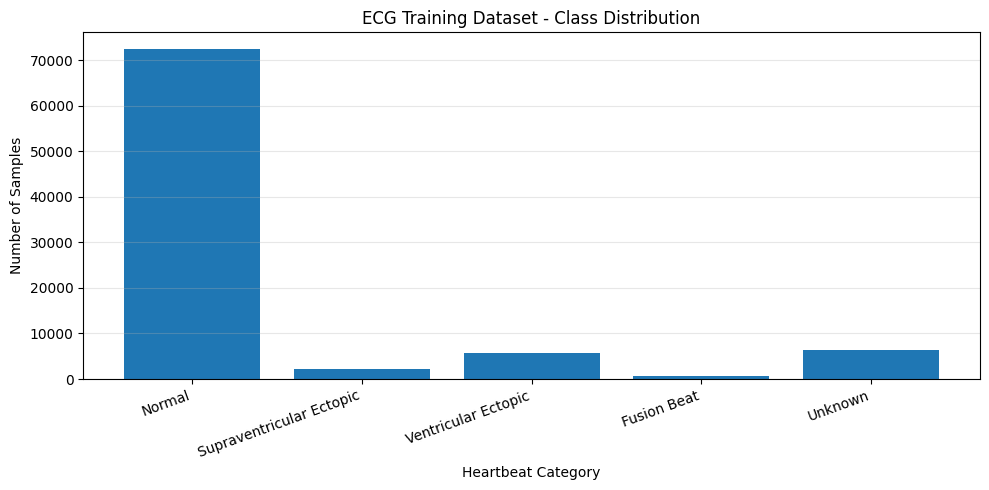

In [ ]:

class_counts = train_df.iloc[:, -1].astype(int).value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(
    [class_names[i] for i in class_counts.index],
    class_counts.values
)
plt.title("ECG Training Dataset - Class Distribution")
plt.xlabel("Heartbeat Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Prepare the data for the CNN

In [ ]:

import numpy as np

# Separate ECG signals (X) and class labels (y)
X_train = train_df.iloc[:, :-1].values
y_train = train_df.iloc[:, -1].values.astype(int)

X_test = test_df.iloc[:, :-1].values
y_test = test_df.iloc[:, -1].values.astype(int)

# Reshape for a 1D CNN: (samples, time steps, channels)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nNumber of classes:", len(np.unique(y_train)))
print("Class labels:", np.unique(y_train))


X_train shape: (87554, 187, 1)
y_train shape: (87554,)
X_test shape: (21892, 187, 1)
y_test shape: (21892,)

Number of classes: 5
Class labels: [0 1 2 3 4]


Split out validation data

In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Test samples:", X_test.shape[0])


Training samples: 74420
Validation samples: 13134
Test samples: 21892


In [ ]:

import pandas as pd

df = pd.read_csv("/content/ecg_data/mitbih_train.csv", header=None)

print(df.shape)
print(df.columns)
print(df.iloc[:, -1].value_counts().sort_index())


(87554, 188)
Index([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,
       ...
       178, 179, 180, 181, 182, 183, 184, 185, 186, 187],
      dtype='int64', length=188)
187
0.0    72471
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64


Import libraries and calculate class weights

In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate weights using only the training labels
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")
print(class_weights)


Class weights:
{0: 0.24162337662337663, 1: 7.879301217575437, 2: 3.0252032520325205, 3: 27.310091743119266, 4: 2.7230150018294914}


Create CNN Architecture

In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    BatchNormalization, Dropout,
    GlobalAveragePooling1D, Dense
)

model = Sequential([
    Input(shape=(187, 1)),

    Conv1D(32, kernel_size=7, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(64, kernel_size=5, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, activation="relu", padding="same"),
    BatchNormalization(),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 187, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 187, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 93, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 93, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 46, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,741 (174.77 KB)

 Trainable params: 44,293 (173.02 KB)

 Non-trainable params: 448 (1.75 KB)

Train the CNN

In [ ]:

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 65s 106ms/step - accuracy: 0.6133 - loss: 0.6802 - val_accuracy: 0.0838 - val_loss: 3.5674
Epoch 2/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 61s 104ms/step - accuracy: 0.7948 - loss: 0.4264 - val_accuracy: 0.8402 - val_loss: 0.5079
Epoch 3/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 81s 103ms/step - accuracy: 0.8311 - loss: 0.3657 - val_accuracy: 0.4419 - val_loss: 2.4486
Epoch 4/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 60s 104ms/step - accuracy: 0.8496 - loss: 0.3261 - val_accuracy: 0.7606 - val_loss: 0.6042
Epoch 5/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 61s 104ms/step - accuracy: 0.8523 - loss: 0.3003 - val_accuracy: 0.8656 - val_loss: 0.3920
Epoch 6/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 82s 104ms/step - accuracy: 0.8668 - loss: 0.2831 - val_accuracy: 0.9420 - val_loss: 0.2421
Epoch 7/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 60s 103ms/step - accuracy: 0.8728 - loss: 0.2645 - val_accuracy: 0.8920 - val_loss: 0.3144
Epoch 8/15
582/582 ━━━━━━━━━━━━━━━━━━━━ 65s 112ms/step - accuracy: 0.8822 - loss: 0

Evaluate the CNN

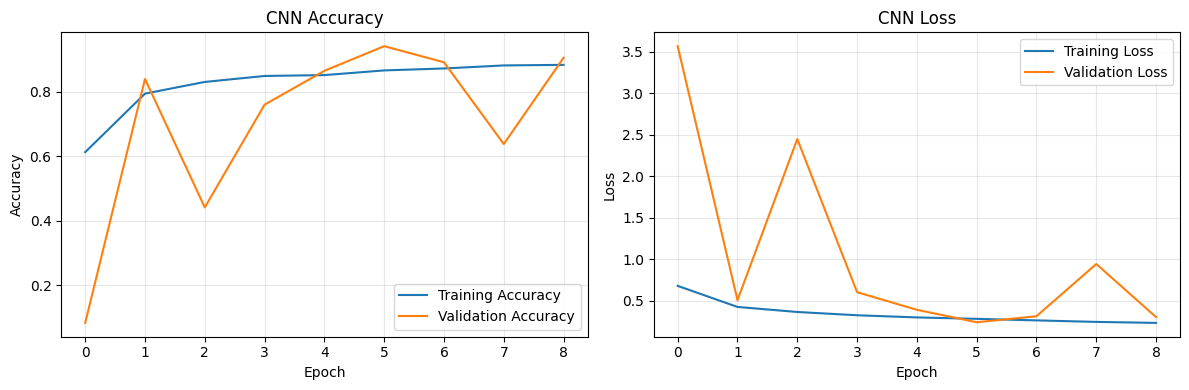

In [ ]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# Evaluate on the untouched test dataset
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=1
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


685/685 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9408 - loss: 0.2460

Test Loss: 0.2460
Test Accuracy: 94.08%


Generate the classification report

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Predict probabilities and convert them to class labels
y_prob = model.predict(X_test, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "Normal",
    "Supraventricular Ectopic",
    "Ventricular Ectopic",
    "Fusion Beat",
    "Unknown"
]

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
))


685/685 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step
                          precision    recall  f1-score   support

                  Normal     0.9832    0.9492    0.9659     18118
Supraventricular Ectopic     0.4141    0.7068    0.5223       556
     Ventricular Ectopic     0.8176    0.9351    0.8724      1448
             Fusion Beat     0.5187    0.7716    0.6203       162
                 Unknown     0.9826    0.9496    0.9658      1608

                accuracy                         0.9408     21892
               macro avg     0.7432    0.8625    0.7894     21892
            weighted avg     0.9543    0.9408    0.9459     21892



Plot the confusion matrix

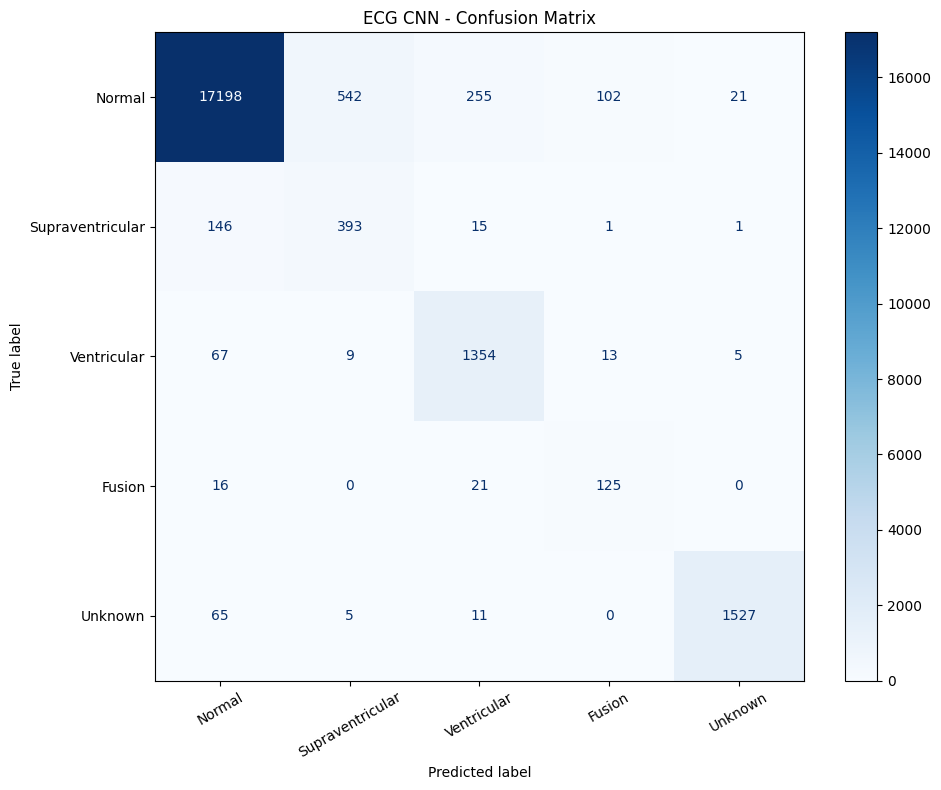

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Supraventricular", "Ventricular", "Fusion", "Unknown"]
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=30)
plt.title("ECG CNN - Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
model.save("/content/ecg_cnn_model.keras")

In [ ]:
#verifying the saved model
import os

print("Model saved successfully:",
      os.path.exists("/content/ecg_cnn_model.keras"))


Model saved successfully: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Improve the model's performance on minority classes

Now we are going to imporve the model performance


Step 1 — Save your baseline model and check the dataset

In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Save the existing trained model
model.save("/content/ecg_cnn_baseline.keras")

print("Baseline model saved successfully!")

# Check dataset sizes
print("\nDataset sizes:")
print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Testing samples:", len(y_test))

# Calculate class weights using training labels only
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("\nClass weights:")
print(class_weights)

# Baseline performance
print("\nBaseline performance:")
print("Test Accuracy: 94.08%")
print("Macro F1-score: 78.94%")
print("Weighted F1-score: 94.59%")

Baseline model saved successfully!

Dataset sizes:
Training samples: 74420
Validation samples: 13134
Testing samples: 21892

Class weights:
{0: 0.24162337662337663, 1: 7.879301217575437, 2: 3.0252032520325205, 3: 27.310091743119266, 4: 2.7230150018294914}

Baseline performance:
Test Accuracy: 94.08%
Macro F1-score: 78.94%
Weighted F1-score: 94.59%


Build Experiment 2: CNN with Focal Loss

In [ ]:

import tensorflow as tf
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    BatchNormalization, Dropout,
    GlobalAveragePooling1D, Dense
)

# Define Sparse Focal Loss
def sparse_focal_loss(gamma=2.0):
    def loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)

        # Calculate probability of the correct class
        y_true_one_hot = tf.one_hot(y_true, depth=5)

        y_pred = tf.clip_by_value(
            y_pred, 1e-7, 1.0 - 1e-7
        )

        p_t = tf.reduce_sum(
            y_true_one_hot * y_pred, axis=-1
        )

        cross_entropy = -tf.math.log(p_t)

        focal_factor = tf.pow(1.0 - p_t, gamma)

        return focal_factor * cross_entropy

    return loss


# Build Experiment 2 CNN
model_focal = Sequential([
    Input(shape=(187, 1)),

    Conv1D(32, kernel_size=7, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(64, kernel_size=5, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, activation="relu", padding="same"),
    BatchNormalization(),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(5, activation="softmax")
])


# Compile using Focal Loss
model_focal.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=sparse_focal_loss(gamma=2.0),
    metrics=["accuracy"]
)

model_focal.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 187, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 187, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 93, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 93, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 46, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,741 (174.77 KB)

 Trainable params: 44,293 (173.02 KB)

 Non-trainable params: 448 (1.75 KB)

Step 3 - Train Experiment 2

In [ ]:

early_stopping_focal = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_focal = model_focal.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=128,
    callbacks=[early_stopping_focal],
    verbose=1
)


Epoch 1/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 69s 111ms/step - accuracy: 0.9290 - loss: 0.1229 - val_accuracy: 0.8215 - val_loss: 0.2345
Epoch 2/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 63s 108ms/step - accuracy: 0.9592 - loss: 0.0576 - val_accuracy: 0.9507 - val_loss: 0.0781
Epoch 3/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 62s 107ms/step - accuracy: 0.9662 - loss: 0.0476 - val_accuracy: 0.9643 - val_loss: 0.0514
Epoch 4/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 82s 108ms/step - accuracy: 0.9698 - loss: 0.0406 - val_accuracy: 0.9596 - val_loss: 0.0468
Epoch 5/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 82s 108ms/step - accuracy: 0.9723 - loss: 0.0367 - val_accuracy: 0.9542 - val_loss: 0.0558
Epoch 6/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 81s 107ms/step - accuracy: 0.9740 - loss: 0.0345 - val_accuracy: 0.9443 - val_loss: 0.0911
Epoch 7/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 83s 108ms/step - accuracy: 0.9756 - loss: 0.0307 - val_accuracy: 0.9682 - val_loss: 0.0395
Epoch 8/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 63s 108ms/step - accuracy: 0.9772 - loss: 0

Step 4 — Plot training graphs

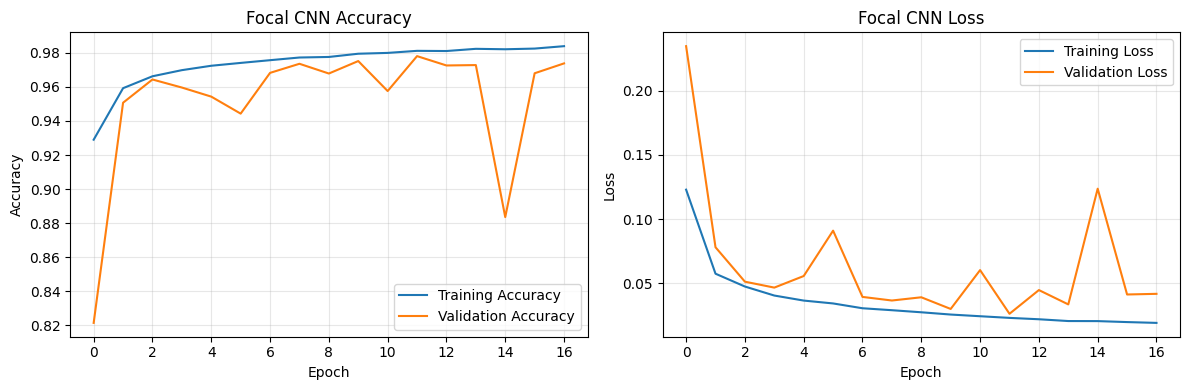

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_focal.history["accuracy"], label="Training Accuracy")
plt.plot(history_focal.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Focal CNN Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_focal.history["loss"], label="Training Loss")
plt.plot(history_focal.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal CNN Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Step 5 — Evaluate Experiment 2

685/685 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step
Test Accuracy: 0.9775717156952312
Macro F1: 0.8678852513480706
Weighted F1: 0.9758991742493824

Classification Report:

                  precision    recall  f1-score   support

          Normal     0.9814    0.9953    0.9883     18118
Supraventricular     0.9475    0.5845    0.7230       556
     Ventricular     0.9442    0.9468    0.9455      1448
          Fusion     0.9118    0.5741    0.7045       162
         Unknown     0.9741    0.9820    0.9780      1608

        accuracy                         0.9776     21892
       macro avg     0.9518    0.8165    0.8679     21892
    weighted avg     0.9771    0.9776    0.9759     21892



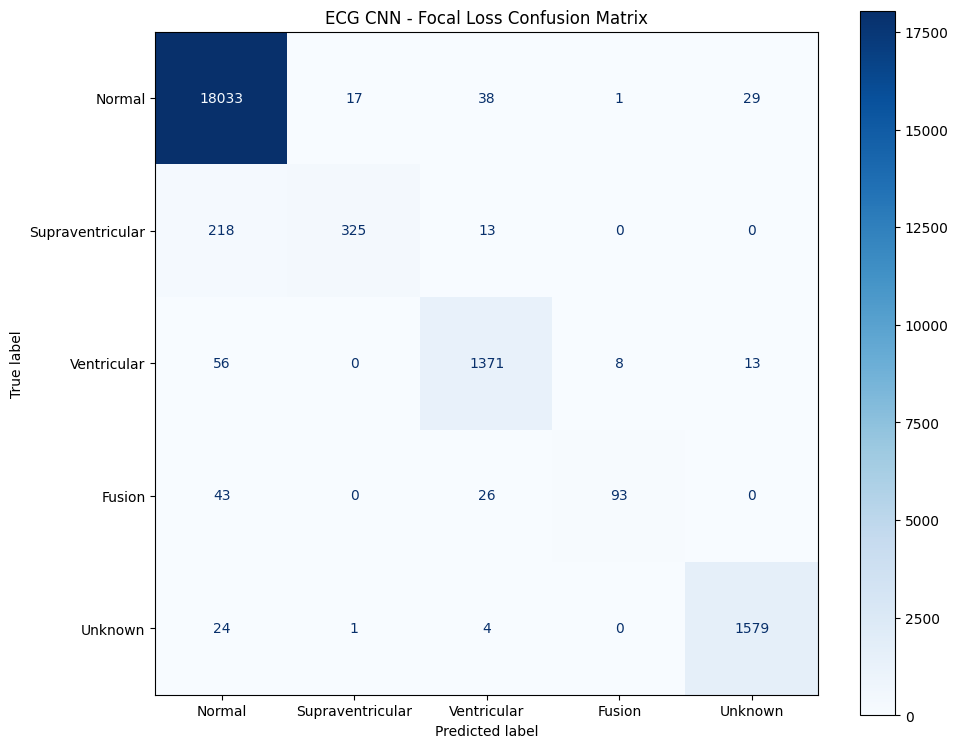

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_focal = np.argmax(
    model_focal.predict(X_test),
    axis=1
)

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_focal))

print("Macro F1:",
      f1_score(y_test, y_pred_focal, average="macro"))

print("Weighted F1:",
      f1_score(y_test, y_pred_focal, average="weighted"))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_focal,
    target_names=[
        "Normal",
        "Supraventricular",
        "Ventricular",
        "Fusion",
        "Unknown"
    ],
    digits=4
))

cm_focal = confusion_matrix(
    y_test,
    y_pred_focal,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_focal,
    display_labels=[
        "Normal", "Supraventricular",
        "Ventricular", "Fusion", "Unknown"
    ]
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("ECG CNN - Focal Loss Confusion Matrix")
plt.tight_layout()
plt.show()


In Experiment 2, Focal Loss improved overall performance, but the model still missed many minority-class ECG beats, particularly Supraventricular and Fusion beats.

We added alpha to give greater importance to underrepresented classes during training.

We introduced Alpha-Balanced Focal Loss to address class imbalance in our ECG dataset. Focal Loss focuses on difficult-to-classify samples, while alpha assigns different importance to each class. Our objective was to improve the detection of minority ECG classes, especially Supraventricular and Fusion beats.


Alpha values: [0.2062929  1.17803625 0.72994827 2.19319063 0.69253196]


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 187, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 187, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 93, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 93, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 46, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,741 (174.77 KB)

 Trainable params: 44,293 (173.02 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 68s 109ms/step - accuracy: 0.8892 - loss: 0.0796 - val_accuracy: 0.2255 - val_loss: 0.2007
Epoch 2/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 66s 113ms/step - accuracy: 0.9383 - loss: 0.0422 - val_accuracy: 0.9451 - val_loss: 0.0332
Epoch 3/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 63s 109ms/step - accuracy: 0.9499 - loss: 0.0348 - val_accuracy: 0.9247 - val_loss: 0.0429
Epoch 4/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 63s 109ms/step - accuracy: 0.9554 - loss: 0.0304 - val_accuracy: 0.9504 - val_loss: 0.0454
Epoch 5/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 63s 108ms/step - accuracy: 0.9592 - loss: 0.0281 - val_accuracy: 0.9672 - val_loss: 0.0289
Epoch 6/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 65s 112ms/step - accuracy: 0.9632 - loss: 0.0254 - val_accuracy: 0.9614 - val_loss: 0.0282
Epoch 7/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 64s 111ms/step - accuracy: 0.9639 - loss: 0.0238 - val_accuracy: 0.9367 - val_loss: 0.0294
Epoch 8/25
582/582 ━━━━━━━━━━━━━━━━━━━━ 63s 109ms/step - accuracy: 0.9667 - loss: 0

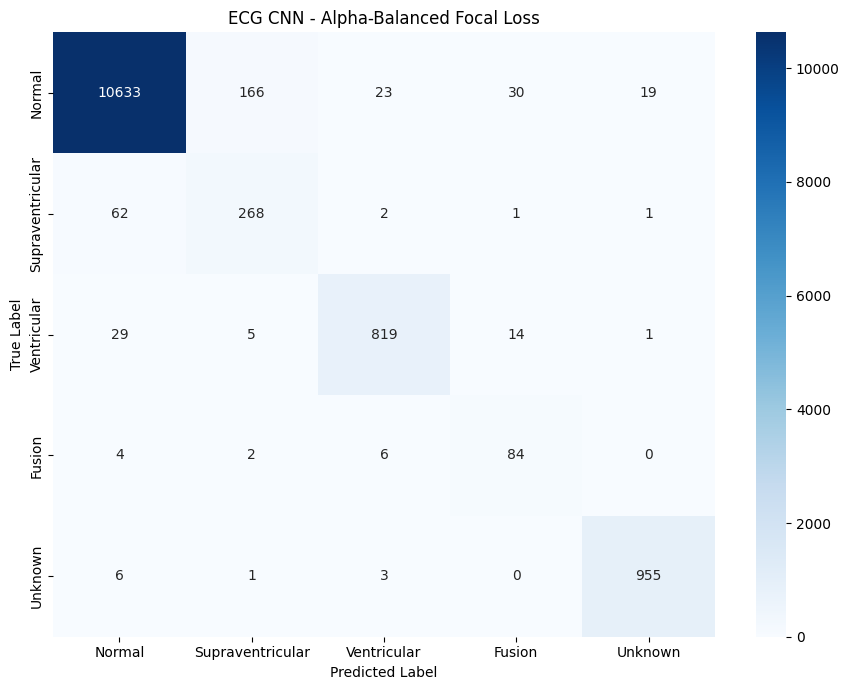

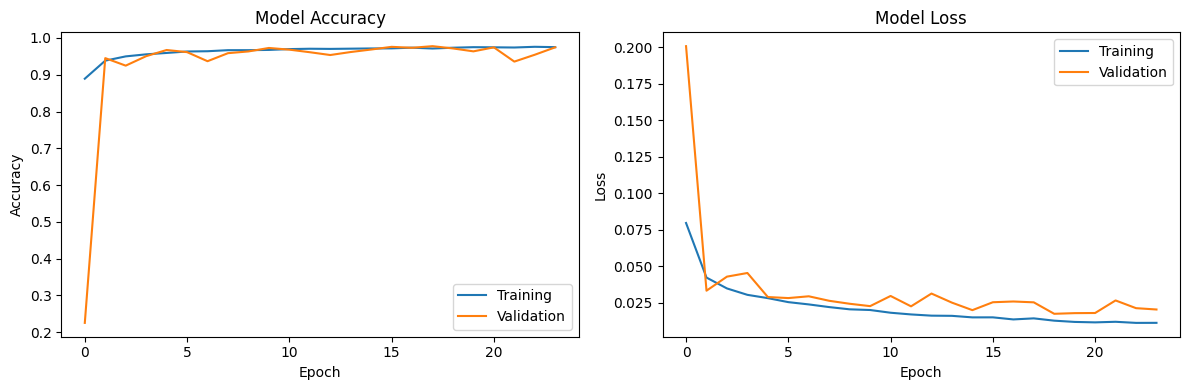


Experiment 3 completed successfully!


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    BatchNormalization, Dropout,
    GlobalAveragePooling1D, Dense
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ==========================================
# STEP 1: DEFINE ALPHA-BALANCED FOCAL LOSS
# ==========================================

def alpha_focal_loss(alpha, gamma=2.0):

    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss(y_true, y_pred):

        y_true = tf.cast(
            tf.reshape(y_true, [-1]), tf.int32
        )

        y_pred = tf.clip_by_value(
            y_pred, 1e-7, 1.0 - 1e-7
        )

        y_true_one_hot = tf.one_hot(
            y_true, depth=5
        )

        p_t = tf.reduce_sum(
            y_true_one_hot * y_pred, axis=-1
        )

        alpha_t = tf.gather(alpha, y_true)

        cross_entropy = -tf.math.log(p_t)

        focal_factor = tf.pow(
            1.0 - p_t, gamma
        )

        return alpha_t * focal_factor * cross_entropy

    return loss


# ==========================================
# STEP 2: CALCULATE ALPHA VALUES
# ==========================================

alpha_values = np.sqrt([
    class_weights[i] for i in range(5)
])

alpha_values = alpha_values / np.mean(alpha_values)

print("Alpha values:", alpha_values)


# ==========================================
# STEP 3: BUILD EXPERIMENT 3 CNN
# ==========================================

model_exp3 = Sequential([

    Input(shape=(187, 1)),

    Conv1D(32, kernel_size=7,
           activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(64, kernel_size=5,
           activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3,
           activation="relu", padding="same"),
    BatchNormalization(),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(5, activation="softmax")
])


# ==========================================
# STEP 4: COMPILE MODEL
# ==========================================

model_exp3.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=alpha_focal_loss(
        alpha=alpha_values,
        gamma=2.0
    ),

    metrics=["accuracy"]
)

model_exp3.summary()


# ==========================================
# STEP 5: EARLY STOPPING
# ==========================================

early_stopping_exp3 = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


# ==========================================
# STEP 6: TRAIN MODEL
# ==========================================

history_exp3 = model_exp3.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=25,
    batch_size=128,

    callbacks=[early_stopping_exp3],

    verbose=1
)


# ==========================================
# STEP 7: VALIDATION PREDICTIONS
# ==========================================

y_val_prob_exp3 = model_exp3.predict(X_val)

y_val_pred_exp3 = np.argmax(
    y_val_prob_exp3, axis=1
)


# ==========================================
# STEP 8: EVALUATE MODEL
# ==========================================

val_accuracy_exp3 = accuracy_score(
    y_val, y_val_pred_exp3
)

val_macro_f1_exp3 = f1_score(
    y_val, y_val_pred_exp3,
    average="macro"
)

val_weighted_f1_exp3 = f1_score(
    y_val, y_val_pred_exp3,
    average="weighted"
)

print("\n========== EXPERIMENT 3 RESULTS ==========")

print(f"Validation Accuracy: {val_accuracy_exp3 * 100:.2f}%")
print(f"Validation Macro F1: {val_macro_f1_exp3 * 100:.2f}%")
print(f"Validation Weighted F1: {val_weighted_f1_exp3 * 100:.2f}%")


# ==========================================
# STEP 9: CLASSIFICATION REPORT
# ==========================================

class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred_exp3,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
))


# ==========================================
# STEP 10: CONFUSION MATRIX
# ==========================================

cm_exp3 = confusion_matrix(
    y_val,
    y_val_pred_exp3,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_exp3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ECG CNN - Alpha-Balanced Focal Loss")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


# ==========================================
# STEP 11: TRAINING AND VALIDATION CURVES
# ==========================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_exp3.history["accuracy"], label="Training")
plt.plot(history_exp3.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_exp3.history["loss"], label="Training")
plt.plot(history_exp3.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


print("\nExperiment 3 completed successfully!")


fair comparison of all three models using the exact same validation dataset.

In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ==========================================
# STEP 1: LOAD BASELINE MODEL
# ==========================================

baseline_model = tf.keras.models.load_model(
    "/content/ecg_cnn_baseline.keras"
)

# ==========================================
# STEP 2: DEFINE ALL THREE MODELS
# ==========================================

models = {
    "Baseline CNN": baseline_model,
    "Focal Loss CNN": model_focal,
    "Alpha-Balanced Focal CNN": model_exp3
}

# ==========================================
# STEP 3: EVALUATE ON SAME VALIDATION DATA
# ==========================================

results = []

class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

for model_name, current_model in models.items():

    y_prob = current_model.predict(
        X_val, verbose=0
    )

    y_pred = np.argmax(y_prob, axis=1)

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Macro Precision (%)": round(precision * 100, 2),
        "Macro Recall (%)": round(recall * 100, 2),
        "Macro F1 (%)": round(macro_f1 * 100, 2),
        "Weighted F1 (%)": round(weighted_f1 * 100, 2)
    })

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

# ==========================================
# STEP 4: DISPLAY FINAL COMPARISON
# ==========================================

comparison_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========\n")

print(
    comparison_df.to_string(index=False)
)

# Best model according to validation macro F1
best_model = comparison_df.loc[
    comparison_df["Macro F1 (%)"].idxmax()
]

print("\nBest model based on validation Macro F1:")
print(best_model.to_string())



Baseline CNN
                  precision    recall  f1-score   support

          Normal     0.9833    0.9492    0.9660     10871
Supraventricular     0.4260    0.7156    0.5341       334
     Ventricular     0.8206    0.9274    0.8707       868
          Fusion     0.5214    0.7604    0.6186        96
         Unknown     0.9770    0.9699    0.9735       965

        accuracy                         0.9420     13134
       macro avg     0.7457    0.8645    0.7926     13134
    weighted avg     0.9546    0.9420    0.9467     13134


Focal Loss CNN
                  precision    recall  f1-score   support

          Normal     0.9837    0.9953    0.9895     10871
Supraventricular     0.9533    0.6108    0.7445       334
     Ventricular     0.9497    0.9574    0.9535       868
          Fusion     0.9242    0.6354    0.7531        96
         Unknown     0.9745    0.9896    0.9820       965

        accuracy                         0.9800     13134
       macro avg     0.9571    0.8377

Baseline CNN: Lowest overall performance. It struggles with minority-class precision.

Focal Loss CNN: Best overall balance according to macro F1. It also achieves the highest accuracy and precision.

Alpha-Balanced Focal CNN: Best macro recall. It detects more minority-class examples, but produces more false-positive predictions.

Look at the minority-class recall:
Class	Focal Loss	Alpha-Balanced
Supraventricular	61.08%	80.24%
Fusion	63.54%	87.50%

This is an important difference.
3. Which model should we select?
My recommendation:

Keep Focal Loss CNN as your primary model, because it achieved the highest validation macro F1-score of 88.45%.

However, retain Alpha-Balanced Focal CNN as a strong alternative. If your project's priority is reducing missed abnormal beats, its higher recall deserves serious consideration.

Save the selected model and evaluate it

Final selected model saved successfully!
685/685 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step

========== FINAL MODEL PERFORMANCE ==========
Test Accuracy: 97.76%
Test Macro F1: 86.79%
Test Weighted F1: 97.59%

FINAL CLASSIFICATION REPORT:

                  precision    recall  f1-score   support

          Normal     0.9814    0.9953    0.9883     18118
Supraventricular     0.9475    0.5845    0.7230       556
     Ventricular     0.9442    0.9468    0.9455      1448
          Fusion     0.9118    0.5741    0.7045       162
         Unknown     0.9741    0.9820    0.9780      1608

        accuracy                         0.9776     21892
       macro avg     0.9518    0.8165    0.8679     21892
    weighted avg     0.9771    0.9776    0.9759     21892



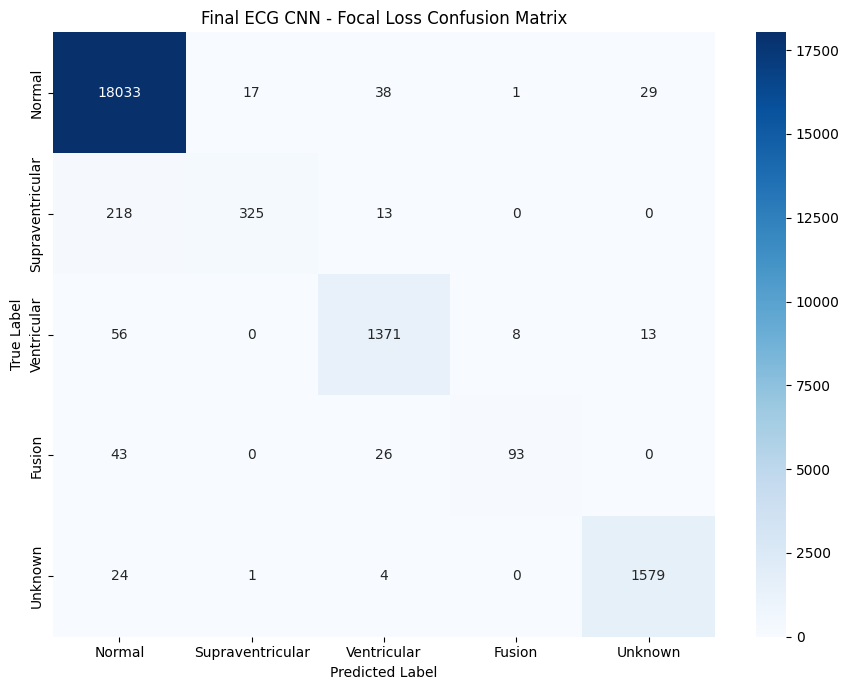

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# ==========================================
# STEP 1: SAVE THE SELECTED MODEL
# ==========================================

model_focal.save("/content/ecg_cnn_final.keras")

print("Final selected model saved successfully!")


# ==========================================
# STEP 2: PREDICT ON TEST DATA
# ==========================================

y_test_prob = model_focal.predict(X_test)

y_test_pred = np.argmax(y_test_prob, axis=1)


# ==========================================
# STEP 3: CALCULATE TEST PERFORMANCE
# ==========================================

test_accuracy = accuracy_score(y_test, y_test_pred)

test_macro_f1 = f1_score(
    y_test, y_test_pred, average="macro"
)

test_weighted_f1 = f1_score(
    y_test, y_test_pred, average="weighted"
)

print("\n========== FINAL MODEL PERFORMANCE ==========")

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Macro F1: {test_macro_f1 * 100:.2f}%")
print(f"Test Weighted F1: {test_weighted_f1 * 100:.2f}%")


# ==========================================
# STEP 4: CLASSIFICATION REPORT
# ==========================================

class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

print("\nFINAL CLASSIFICATION REPORT:\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
))


# ==========================================
# STEP 5: CONFUSION MATRIX
# ==========================================

cm_final = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Final ECG CNN - Focal Loss Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [ ]:
import os
from google.colab import files

model_path = "/content/ecg_cnn_final.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)

    print(f"Model found! Size: {size_mb:.2f} MB")

    files.download(model_path)
else:
    print("Model file not found. Please check the save location.")

Model found! Size: 0.57 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

We are making the files of testing the prediction for 5 classes

In [ ]:
import pandas as pd

# Select one genuine Normal heartbeat (class 0)
sample = train_df[train_df.iloc[:, -1] == 0].iloc[0]

# Extract the 187 ECG signal values
ecg_signal = sample.iloc[:-1].astype(float)

# Save as CSV
pd.DataFrame([ecg_signal.values]).to_csv(
    "genuine_ecg_heartbeat.csv",
    index=False,
    header=False
)

print("Number of ECG values:", len(ecg_signal))
print("Actual class label:", int(sample.iloc[-1]))
print("CSV saved successfully!")

Number of ECG values: 187
Actual class label: 0
CSV saved successfully!


In [ ]:
from google.colab import files
files.download("genuine_ecg_heartbeat.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

class_names = {
    1: "Supraventricular",
    2: "Ventricular",
    3: "Fusion",
    4: "Unknown"
}

for class_id, class_name in class_names.items():

    # Select one genuine heartbeat from this class
    sample = train_df[train_df.iloc[:, -1] == class_id].iloc[0]

    # Extract its 187 ECG values
    ecg_signal = sample.iloc[:-1].astype(float)

    # Save as a CSV
    filename = f"genuine_class_{class_id}.csv"

    pd.DataFrame([ecg_signal.values]).to_csv(
        filename,
        index=False,
        header=False
    )

    print(f"{class_name}: {len(ecg_signal)} values saved to {filename}")

Supraventricular: 187 values saved to genuine_class_1.csv
Ventricular: 187 values saved to genuine_class_2.csv
Fusion: 187 values saved to genuine_class_3.csv
Unknown: 187 values saved to genuine_class_4.csv


In [ ]:
from google.colab import files

for class_id in range(1, 5):
    files.download(f"genuine_class_{class_id}.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>